Task 1

In [2]:
# Import modules
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import modules for machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import confusion_matrix

In [11]:
df = pd.read_csv('data/Titanic_Cleaned.csv', sep=',')
df.head(5)

,PassengerId,Survived,Pclass,SibSp,Parch,HasCabin,CatAge,CatFare,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Unique
0,1,0.0,3,1,0,False,0,0,True,False,True,False,True,False,False
1,2,1.0,1,1,0,True,3,3,False,False,False,False,False,True,False
2,3,1.0,3,0,0,False,1,1,False,False,True,True,False,False,False
3,4,1.0,1,1,0,True,2,3,False,False,True,False,False,True,False
4,5,0.0,3,0,0,False,2,1,True,False,True,False,True,False,False


In [16]:
df_train = df[df['Survived'].notnull()]
df_test = df[df['Survived'].isnull()]

df_train.to_csv('data/train2.csv', index=False)
df_test.to_csv('data/test2.csv', index=False)

print(f"Training set shape: {df_train.shape}")
print(f"Test set shape: {df_test.shape}")


Training set shape: (891, 15)
Test set shape: (418, 15)


Task 2

In [17]:
df_train['TravelAlone'] = (df_train['SibSp'] + df_train['Parch'] == 0).astype(int)

In [23]:
df_train = df_train.drop(columns=['Parch'])
df_train = df_train.drop(columns=['SibSp'])

KeyError: "['Parch'] not found in axis"

In [24]:
df_train.head(5)

,PassengerId,Survived,Pclass,HasCabin,CatAge,CatFare,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Unique,TravelAlone
0,1,0.0,3,False,0,0,True,False,True,False,True,False,False,0
1,2,1.0,1,True,3,3,False,False,False,False,False,True,False,0
2,3,1.0,3,False,1,1,False,False,True,True,False,False,False,1
3,4,1.0,1,True,2,3,False,False,True,False,False,True,False,0
4,5,0.0,3,False,2,1,True,False,True,False,True,False,False,1


Task 3

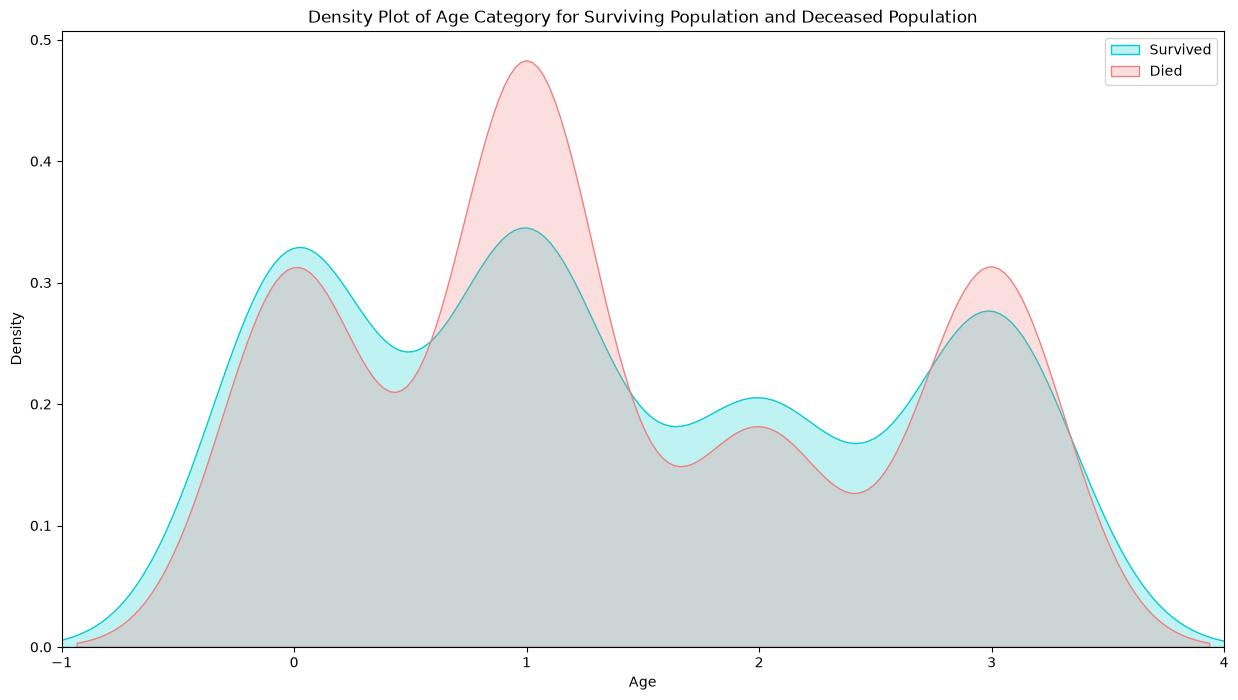

In [25]:
plt.figure(figsize=(15,8))
ax = sns.kdeplot(df_train["CatAge"][df_train.Survived == 1], color="darkturquoise", fill=True)
sns.kdeplot(df_train["CatAge"][df_train.Survived == 0], color="lightcoral", fill=True)
plt.legend(['Survived', 'Died'])
plt.title('Density Plot of Age Category for Surviving Population and Deceased Population')
ax.set(xlabel='Age')
plt.xlim(-1,4)
plt.show()


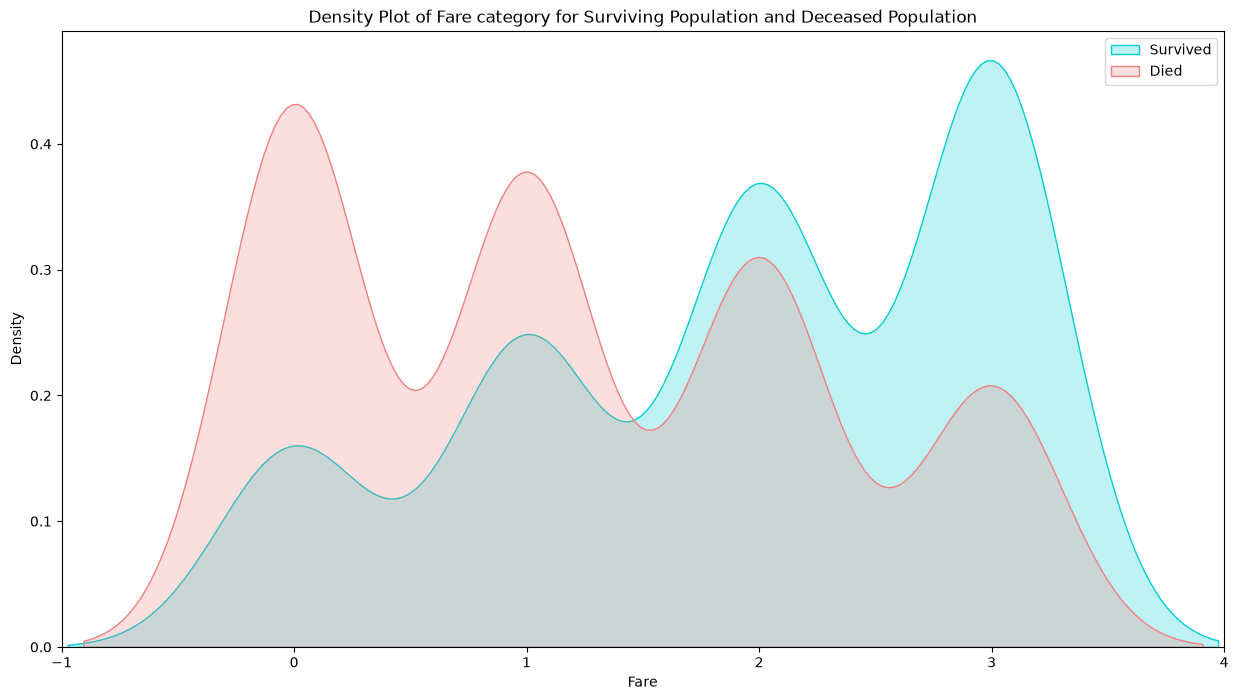

In [28]:
plt.figure(figsize=(15,8))
ax = sns.kdeplot(df_train["CatFare"][df_train.Survived == 1], color="darkturquoise", fill=True)
sns.kdeplot(df_train["CatFare"][df_train.Survived == 0], color="lightcoral", fill=True)
plt.legend(['Survived', 'Died'])
plt.title('Density Plot of Fare category for Surviving Population and Deceased Population')
ax.set(xlabel='Fare')
plt.xlim(-1,4)
plt.show()


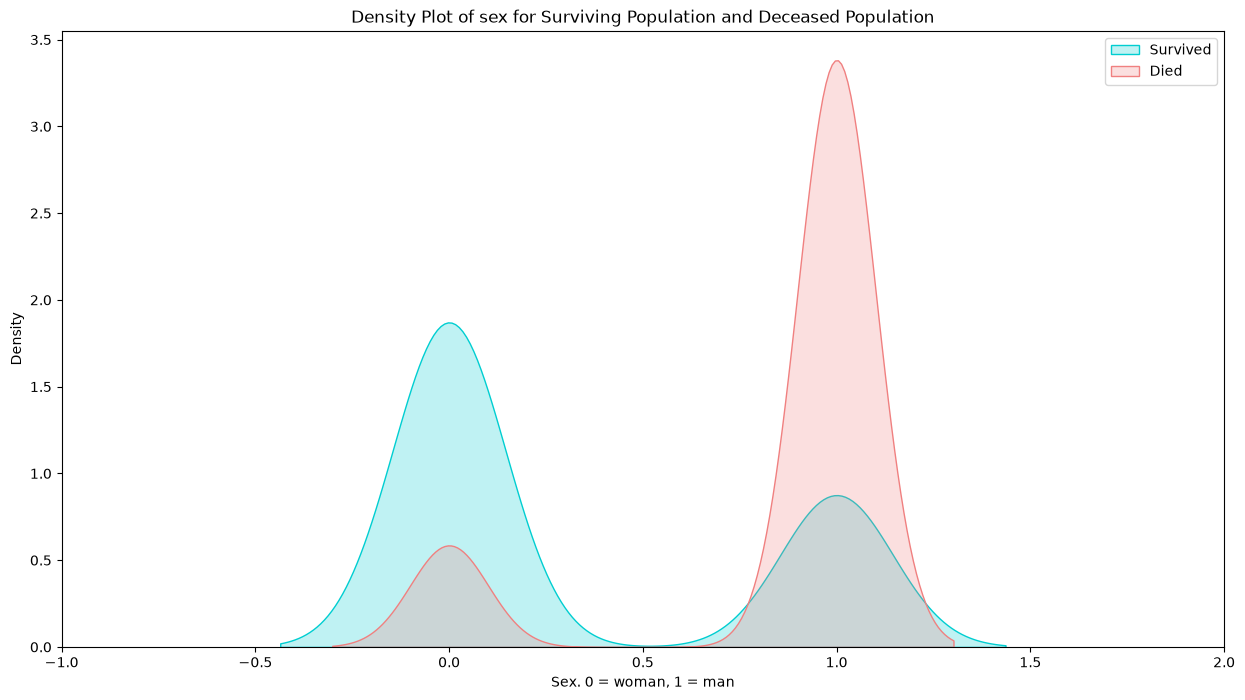

In [34]:
plt.figure(figsize=(15,8))
ax = sns.kdeplot(df_train["Sex_male"][df_train.Survived == 1], color="darkturquoise", fill=True)
sns.kdeplot(df_train["Sex_male"][df_train.Survived == 0], color="lightcoral", fill=True)
plt.legend(['Survived', 'Died'])
plt.title('Density Plot of sex for Surviving Population and Deceased Population')
ax.set(xlabel='Sex. 0 = woman, 1 = man')
plt.xlim(-1,2)
plt.show()


Task 4

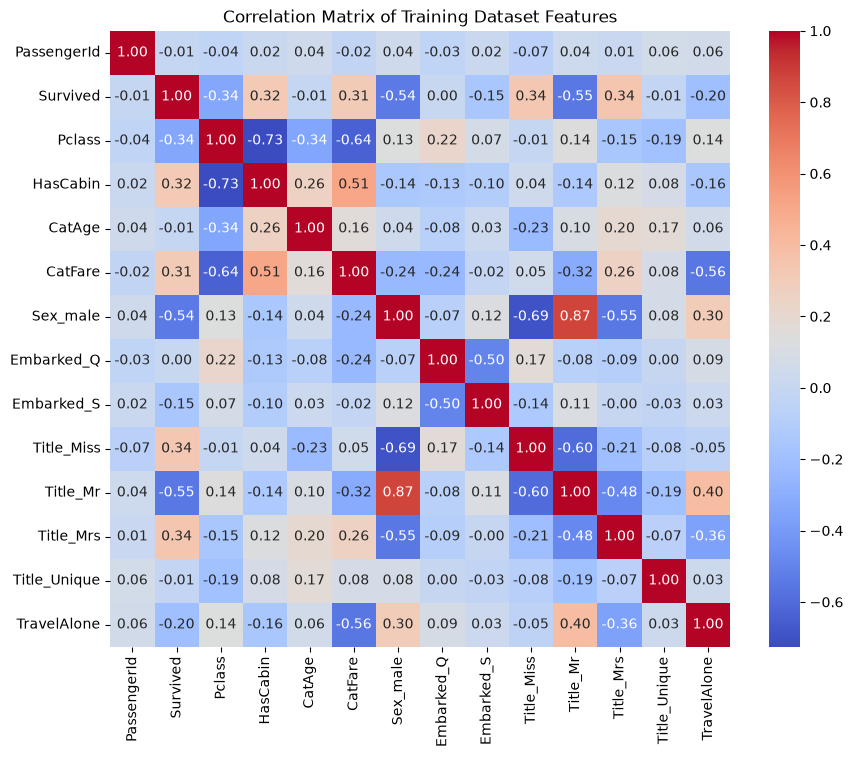

In [35]:
# Compute correlation matrix
correlation_matrix = df_train.corr()

#Visualize the Correlation Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Training Dataset Features')
plt.show()


Task 5

In [38]:
X = df_train.drop(['PassengerId', 'Survived'], axis=1)
y = df_train['Survived']

In [39]:
model = LogisticRegression(max_iter=1000)


In [44]:
rfe = RFE(estimator=model, n_features_to_select=8)
rfe.fit(X, y)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",LogisticRegre...max_iter=1000)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",8
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[float64](2,)","[0.,1.]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,LogisticRegression,LogisticRegre...max_iter=1000)
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['Pclass','HasCabin','CatAge',...,'Title_Mrs','Title_Unique','TravelAlone']"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(8)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,12


In [41]:
selected_features = X.columns[rfe.support_]
print('Selected features:', selected_features)


Selected features: Index(['Pclass', 'HasCabin', 'Sex_male', 'Embarked_S', 'Title_Miss',
       'Title_Mr', 'Title_Unique', 'TravelAlone'],
      dtype='str')


Task 6

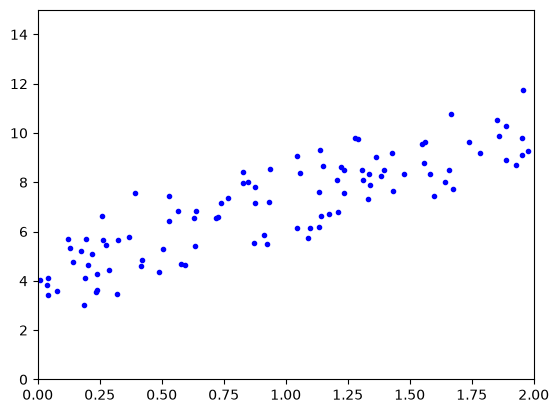

In [1]:
# create simple lin regression model
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# create some data
np.random.seed(0)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

# plot the data
plt.plot(X, y, "b.")
plt.axis([0, 2, 0, 15])
plt.show()


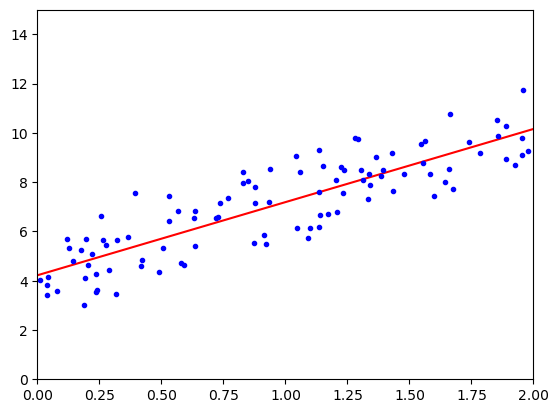

intercept:  [4.22215108]
coefficients:  [[2.96846751]]
score:  0.7469629925504755


In [2]:

# create a linear regression model
lin_reg = LinearRegression()
lin_reg.fit(X, y)

# make predictions
X_new = np.array([[0], [2]]) 
y_predict = lin_reg.predict(X_new) # make predictions 

# plot the data
plt.plot(X_new, y_predict, "r-")
plt.plot(X, y, "b.")
plt.axis([0, 2, 0, 15])
plt.show()

# print the model parameters
print("intercept: ", lin_reg.intercept_)
print("coefficients: ", lin_reg.coef_)
print("score: ", lin_reg.score(X, y))
